# Avance 2. Ingeniería de características

**Equipo 51** · Proyecto Integrador, Maestría en Inteligencia Artificial Aplicada (MNA)
**Proyecto:** AI Co-Pilot Video-to-SOP (patrocinador: Alignity)

## 0. Introducción

**Objetivo del avance.** Construir, transformar, escalar y seleccionar las características con las que se entrenará un clasificador binario de `has_errors`: dado un paso ejecutado en una grabación, ¿se hizo con error? Cada decisión se respalda con una prueba o un resultado sobre la partición de entrenamiento.

**Vínculo con el avance 1.** Se usan las mismas anotaciones públicas de **CaptainCook4D** (commit fijo, licencia MIT), la misma partición oficial por grabación y las mismas funciones de preprocesamiento. Esas funciones ya no viven en el notebook: se movieron sin cambios al paquete del proyecto (`sopvid.features`) y se verificó que reproducen exactamente las tablas del avance 1 (sección 2). Los hallazgos del EDA que motivan este avance son: la duración absoluta no distingue errores pero la relativa a su paso sí; la posición en el procedimiento importa; `step_id` y `verb` tienen alta cardinalidad; la duración es log-normal y tiene atípicos.

**Vínculo con el producto.** El copiloto indexa cada video en pasos con su segundo exacto. Un modelo que estima qué pasos se ejecutaron con error es la base de las **advertencias** del copiloto: marcar, para revisión humana, los pasos sospechosos de un video antes de convertirlo en SOP. Por eso las características se limitan a lo que el sistema puede observar de un video segmentado (tiempos, orden y tipo de paso) y se excluye todo lo que solo existe en la anotación.

**Regla anti-fuga.** Todo lo que aprende de los datos (duración típica de cada paso, codificadores, transformaciones, escaladores, selección y PCA) se ajusta **solo con entrenamiento**, dentro de un `Pipeline` de scikit-learn. Las codificaciones que usan estadísticas por categoría se calculan **fuera de pliegue** con `GroupKFold` por grabación. Validación y prueba solo se transforman al final, sin mirar sus etiquetas.

**Metodología.** CRISP-ML(Q), fase de *Data Preparation* (Studer et al., 2021).

> **Nota de ejecución:** la libreta se corre de principio a fin (*Kernel → Restart & Run All*). Requiere el paquete del proyecto instalado (`pip install -e ".[dev]"` desde la raíz del repositorio) y conexión a internet la primera vez para descargar ~5 MB de anotaciones.

## 1. Configuración del entorno

Todo el código de características se importa de `sopvid.features`:

| Módulo | Contenido |
|---|---|
| `data` | Descarga del commit fijo, tabla a nivel paso y grafos de las recetas |
| `preprocessing` | Partición oficial y preprocesamiento del avance 1 |
| `engineering` | Características nuevas, transformadores sin fuga y `build_features` |

In [1]:
import warnings

import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scipy
import seaborn as sns
import sklearn
from scipy import stats
from sklearn.base import clone
from sklearn.decomposition import PCA
from sklearn.feature_selection import VarianceThreshold, chi2, f_classif, mutual_info_classif
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import PowerTransformer

import sopvid
from sopvid.features import data
from sopvid.features import engineering as fe
from sopvid.features import preprocessing as pp
from sopvid.plataforma.config import PROJECT_ROOT

%matplotlib inline
warnings.filterwarnings("ignore", category=FutureWarning)
# mutual_info_classif con variables discretas guardadas como float (tras escalar): mismo
# resultado, pero sklearn avisa en cada llamada.
warnings.filterwarnings("ignore", message="Clustering metrics expects discrete values")

SEED = fe.SEED  # 51, igual que en el avance 1
np.random.seed(SEED)

pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 160)
pd.set_option("display.float_format", lambda x: f"{x:,.3f}")
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 100

print("sopvid", sopvid.__version__, "| pandas", pd.__version__, "| numpy", np.__version__,
      "| scipy", scipy.__version__, "| sklearn", sklearn.__version__,
      "| matplotlib", matplotlib.__version__, "| seaborn", sns.__version__)

sopvid 0.1.0 | pandas 3.0.6 | numpy 2.4.6 | scipy 1.17.1 | sklearn 1.9.1 | matplotlib 3.11.2 | seaborn 0.13.2


## 2. Datos y continuidad con el avance 1

Se descargan las anotaciones del mismo *commit* del avance 1 a `DATA_DIR` (variable del `.env`, por defecto `data/raw/captaincook4d` en la raíz del repositorio, ignorada por Git). En este avance se agregan los **grafos de tareas** de las 24 recetas (`task_graphs/`, mismo *commit*), que describen qué pasos deben ocurrir antes de cuáles.

In [2]:
raw = data.load_raw()
DATA_PATH = data.default_data_dir()
print("DATA_DIR:", DATA_PATH.relative_to(PROJECT_ROOT) if DATA_PATH.is_relative_to(PROJECT_ROOT) else DATA_PATH)
print("Pasos desalineados entre fuentes:", data.count_misaligned(raw.complete, raw.errors_raw))

steps = data.build_step_table(raw.complete, raw.errors_raw)
parts = pp.split_steps(steps, raw.splits)
graphs = data.load_task_graphs(steps["activity_name"].unique())
TAG_COLS = data.error_tag_columns(steps)

print("Tabla a nivel paso:", steps.shape, "| grafos de receta:", len(graphs))
pd.DataFrame({k: {"grabaciones": v["recording_id"].nunique(), "pasos": len(v)}
              for k, v in parts.items()}).T

DATA_DIR: data\raw\captaincook4d
Pasos desalineados entre fuentes: 0
Tabla a nivel paso: (5700, 23) | grafos de receta: 24


,grabaciones,pasos
train,213,3158
val,62,929
test,109,1613


In [3]:
# Continuidad: las funciones del paquete reproducen el preprocesamiento del avance 1
PARAMS_A1 = pp.fit_preprocess(parts["train"], raw.video_info)
a1 = pp.preprocess(parts["train"], PARAMS_A1, raw.video_info)
pd.Series({
    "pasos de entrenamiento": len(a1),
    "% has_errors (todos los pasos)": round(100 * a1[pp.TARGET].mean(), 3),
    "pasos omitidos (tiempos = -1)": int(a1["is_skipped"].sum()),
    "clases de verb_grouped": a1["verb_grouped"].nunique(),
    "límite inferior de winsorización (s)": round(float(np.expm1(PARAMS_A1["outliers"]["log_p01"])), 2),
    "límite superior de winsorización (s)": round(float(np.expm1(PARAMS_A1["outliers"]["log_p99"])), 2),
}, name="valor").to_frame()

,valor
pasos de entrenamiento,"3,158.000"
% has_errors (todos los pasos),28.879
pasos omitidos (tiempos = -1),171.000
clases de verb_grouped,19.000
límite inferior de winsorización (s),2.990
límite superior de winsorización (s),285.560


Los valores coinciden con el avance 1 (3,158 pasos, 28.9 % con error, 171 omitidos, 19 clases de verbo y límites de 2.99 s y 285.56 s). Al migrar las funciones, las tablas procesadas de train, validación y prueba se compararon columna por columna con las que genera el notebook del avance 1 (idénticas), y `tests/test_features_avance1.py` fija estos valores como prueba de regresión.

### 2.1 Verificación de las columnas necesarias

Antes de construir cualquier característica se comprueba que existan las columnas de las que depende.

In [4]:
NEEDED = {
    "tabla de pasos": (parts["train"], ["recording_id", "activity_name", "step_order", "step_id",
                                        "description", "verb", "start_time", "end_time", "has_errors"]),
    "metadatos de video": (raw.video_info, ["recording_id", "duration(sec)", "person_id"]),
}
rows = [(fuente, col, col in df.columns) for fuente, (df, cols) in NEEDED.items() for col in cols]
check = pd.DataFrame(rows, columns=["fuente", "columna", "existe"])
recetas_sin_grafo = sorted(set(steps["activity_name"]) - set(graphs))
display(check)
print("Recetas sin grafo de tareas:", recetas_sin_grafo or "ninguna")
assert check["existe"].all() and not recetas_sin_grafo

,fuente,columna,existe
0,tabla de pasos,recording_id,True
1,tabla de pasos,activity_name,True
2,tabla de pasos,step_order,True
3,tabla de pasos,step_id,True
4,tabla de pasos,description,True
5,tabla de pasos,verb,True
6,tabla de pasos,start_time,True
7,tabla de pasos,end_time,True
8,tabla de pasos,has_errors,True
9,metadatos de video,recording_id,True


Recetas sin grafo de tareas: ninguna


### 2.2 Unidad de análisis: pasos ejecutados

Tres decisiones previas a la construcción, tomadas con evidencia del avance 1 y de esta celda:

1. **Solo entrenamiento.** Todo se ajusta y se analiza con las 213 grabaciones de entrenamiento. Validación y prueba quedan selladas hasta la sección 5.
2. **Se modelan solo los pasos ejecutados.** Un paso omitido (tiempos = −1) es, por definición, un error *Missing Step*: usarlo como fila haría que `is_skipped` revelara la etiqueta. En el producto, un paso sin segmento de video no pasa por el modelo; se detecta por regla, comparando contra el SOP.
3. **La duración típica de cada paso se calcula fuera de pliegue.** En el avance 1, la mediana de cada `step_id` incluía a la propia fila.

In [5]:
train_all = fe.add_step_features(parts["train"], raw.video_info, graphs)
sk = train_all["is_skipped"]

# Duración relativa del avance 1 (mediana en la misma muestra) vs fuera de pliegue
oof = fe.StepDurationEncoder().fit_transform(fe.executed_steps(train_all)[["step_id", "recording_id", "duration"]])
pd.DataFrame({
    "pasos": [int(sk.sum()), int((~sk).sum())],
    "% con error": [100 * train_all.loc[sk, "has_errors"].mean(), 100 * train_all.loc[~sk, "has_errors"].mean()],
    "dur_ratio_step == 0 exacto (avance 1)": [int((a1.loc[a1["is_skipped"], "dur_ratio_step"] == 0).sum()),
                                              int((a1.loc[~a1["is_skipped"], "dur_ratio_step"] == 0).sum())],
    "dur_ratio_step == 0 exacto (fuera de pliegue)": [np.nan, int((oof[:, 0] == 0).sum())],
}, index=["omitidos", "ejecutados"])

,pasos,% con error,dur_ratio_step == 0 exacto (avance 1),dur_ratio_step == 0 exacto (fuera de pliegue)
omitidos,171,98.246,171,NaN
ejecutados,2987,24.908,173,0.000


In [6]:
train = fe.executed_steps(train_all).copy()
y = train[pp.TARGET].astype(int)
BASE_AP = y.mean()
print("Filas del modelo (pasos ejecutados de entrenamiento):", len(train), "| grabaciones:", train["recording_id"].nunique())
print(f"Proporción de pasos con error: {100 * BASE_AP:.2f} % -> AUC-PR de un clasificador sin información = {BASE_AP:.3f}")

Filas del modelo (pasos ejecutados de entrenamiento): 2987 | grabaciones: 213
Proporción de pasos con error: 24.91 % -> AUC-PR de un clasificador sin información = 0.249


**Justificación :** Los 171 pasos omitidos de entrenamiento tienen error en el 98.2 % de los casos, contra 24.9 % de los pasos ejecutados. Como fila del modelo, `is_skipped` revelaría la etiqueta casi por completo, así que se excluyen. El modelo queda con 2,987 pasos ejecutados de 213 grabaciones y 24.9 % de positivos; ese 0.249 es el AUC-PR de referencia de un clasificador sin información y debe reportarse junto a cada AUC-PR. Además, con la mediana calculada en la misma muestra (como en el avance 1), todos los pasos omitidos y 173 ejecutados tenían `dur_ratio_step` exactamente en 0, un artefacto que no existe en validación ni en prueba. Calculada fuera de pliegue, ningún paso ejecutado queda en 0.

## 3. Construcción, transformación y escalamiento (A)

Para cada grupo de características nuevas se mide su relación con `has_errors` en entrenamiento:

- **Numéricas:** medianas por clase, prueba de **Mann-Whitney U** (no asume normalidad) y **correlación biserial de rangos** como tamaño del efecto (−1 a 1; positivo = mayor en los pasos con error).
- **Binarias:** tasa de error con y sin la característica y **χ²** de independencia.

Las características que **no aprenden** de los datos (posición, contexto, orden y nivel grabación) solo usan la propia grabación y nunca la etiqueta: `fe.add_step_features`.

In [7]:
def compare_num(df, cols, y):
    rows = []
    for c in cols:
        x = df[c].astype(float)
        x0, x1 = x[y == 0], x[y == 1]
        u, p = stats.mannwhitneyu(x1, x0)
        rows.append({"característica": c, "mediana_sin_error": x0.median(), "mediana_con_error": x1.median(),
                     "media_sin_error": x0.mean(), "media_con_error": x1.mean(),
                     "biserial_rangos": 2 * u / (len(x1) * len(x0)) - 1, "p_mann_whitney": p})
    return pd.DataFrame(rows).set_index("característica")


def cv_row(name, prep):
    # AUC-PR con GroupKFold (5 pliegues por grabación) de una regresión logística balanceada
    s = fe.grouped_cv_auc_pr(fe.make_model(prep), train, y)
    n_cols = prep.fit(train, y).transform(train.head(5)).shape[1]
    return {"configuración": name, "columnas": n_cols, "AUC-PR media": s.mean(), "desv.": s.std(),
            **{f"pliegue {i + 1}": v for i, v in enumerate(s)}}


def compare_bin(df, cols, y):
    rows = []
    for c in cols:
        x = df[c].astype(int)
        chi2_, p, _, _ = stats.chi2_contingency(pd.crosstab(x, y))
        rows.append({"característica": c, "% filas = 1": 100 * x.mean(), "% error si = 1": 100 * y[x == 1].mean(),
                     "% error si = 0": 100 * y[x == 0].mean(), "chi2": chi2_, "p": p})
    return pd.DataFrame(rows).set_index("característica")

### 3.1 Duración del paso y duración relativa a su `step_id`

- `duration`: fin − inicio (s).
- `dur_ratio_step` = log(duración / mediana de ese `step_id` en entrenamiento): el cociente del avance 1, ahora **fuera de pliegue**.
- `dur_z_step`: *z-score* de log(duración) dentro del mismo `step_id` (si el paso tiene menos de 3 casos se usa la desviación global).

Ambas se calculan con `fe.StepDurationEncoder`, que en entrenamiento codifica cada grabación con las estadísticas de las demás (GroupKFold, 5 pliegues).

In [8]:
dur = fe.StepDurationEncoder().fit_transform(train[["step_id", "recording_id", "duration"]])
eda = train.assign(dur_ratio_step=dur[:, 0], dur_z_step=dur[:, 1], log_duration=np.log1p(train["duration"]))
compare_num(eda, ["duration", "log_duration", "dur_ratio_step", "dur_z_step"], y)

,mediana_sin_error,mediana_con_error,media_sin_error,media_con_error,biserial_rangos,p_mann_whitney
característica,,,,,,
duration,34.829,37.679,53.995,52.525,0.033,0.176
log_duration,3.579,3.655,3.578,3.620,0.033,0.176
dur_ratio_step,0.041,-0.147,0.036,-0.160,-0.191,0.000
dur_z_step,0.129,-0.276,0.199,-0.445,-0.178,0.000


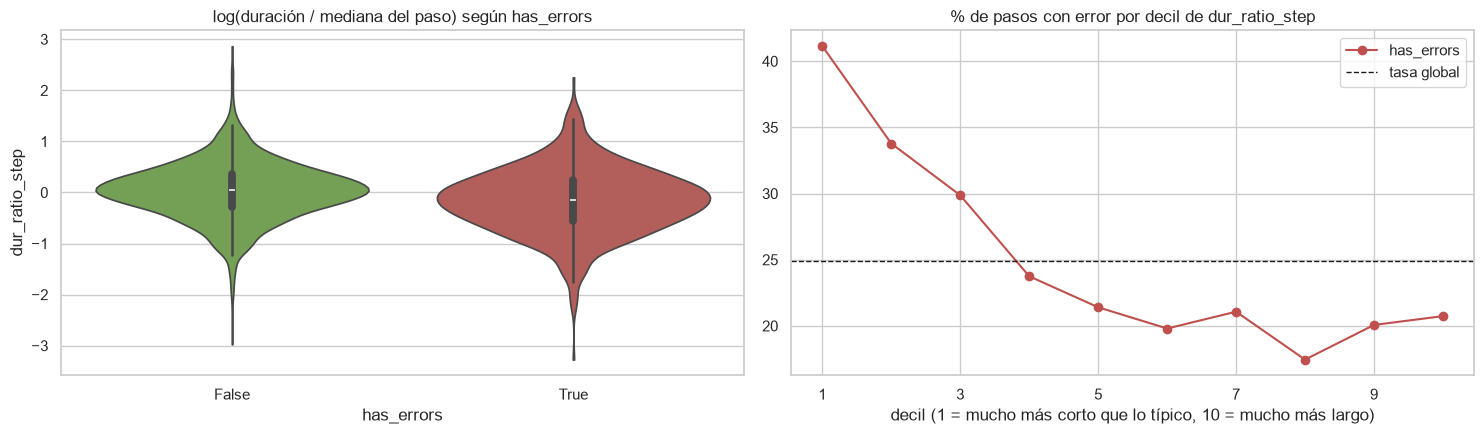

% de pasos con error por decil de dur_ratio_step: {1: 41.1, 2: 33.8, 3: 29.9, 4: 23.7, 5: 21.4, 6: 19.8, 7: 21.1, 8: 17.4, 9: 20.1, 10: 20.7}


In [9]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
sns.violinplot(data=eda, x="has_errors", y="dur_ratio_step", hue="has_errors", legend=False, cut=0,
               palette=["#70ad47", "#c0504d"], ax=axes[0])
axes[0].set_title("log(duración / mediana del paso) según has_errors")
q = pd.qcut(eda["dur_ratio_step"], 10, labels=range(1, 11))
dec_rate = 100 * y.groupby(q, observed=True).mean()
dec_rate.plot(marker="o", color="#c0504d", ax=axes[1])
axes[1].axhline(100 * BASE_AP, color="k", ls="--", lw=1, label="tasa global")
axes[1].set_title("% de pasos con error por decil de dur_ratio_step")
axes[1].set_xlabel("decil (1 = mucho más corto que lo típico, 10 = mucho más largo)"); axes[1].legend()
plt.tight_layout(); plt.show()
print("% de pasos con error por decil de dur_ratio_step:", dec_rate.round(1).to_dict())

**Justificación :** La duración absoluta no distingue pasos con y sin error (Mann-Whitney p = 0.18; biserial de rangos 0.03), igual que en el avance 1. Comparada con la duración típica de su propio paso sí hay señal: los pasos con error duran en mediana alrededor de 14 % menos que lo típico (`dur_ratio_step` = −0.15, contra +0.04 sin error; biserial −0.19, p < 0.001). Los deciles lo muestran mejor: en el 10 % de pasos más cortos respecto a lo típico, la tasa de error es 41.1 % y baja de forma monótona a 23.7 % en el cuarto decil; del quinto al décimo se mantiene entre 17.4 % y 21.4 %, por debajo del 24.9 % global. Lo anómalo es ir **más rápido** de lo normal, no más lento, lo que es coherente con pasos hechos con prisa o incompletos. El *z-score* muestra una relación parecida (biserial −0.18), pero con una mediana de 8 filas por paso su desviación por paso es inestable (asimetría 42.8 en la sección 3.8). Se construyen las dos variantes y la elección se deja a la prueba de correlación (4.2).

### 3.2 Posición del paso

Se calcula sobre los pasos **ejecutados**, ordenados por su inicio (`step_order` sigue el orden de la anotación, que no siempre coincide con el de ejecución cuando hay pasos en paralelo):

- `exec_idx`: índice ordinal de ejecución (0 = primero).
- `rel_exec_pos`: `exec_idx` / (pasos ejecutados − 1), de 0 a 1.
- `rel_start`: inicio del paso / duración del video.
- `is_first`, `is_last`: primer y último paso ejecutado.

In [10]:
display(compare_num(train, ["exec_idx", "rel_exec_pos", "rel_start"], y))
display(compare_bin(train, ["is_first", "is_last"], y))

,mediana_sin_error,mediana_con_error,media_sin_error,media_con_error,biserial_rangos,p_mann_whitney
característica,,,,,,
exec_idx,7.000,5.000,7.601,6.044,-0.162,0.000
rel_exec_pos,0.500,0.455,0.511,0.466,-0.084,0.001
rel_start,0.522,0.489,0.513,0.479,-0.068,0.005


,% filas = 1,% error si = 1,% error si = 0,chi2,p
característica,,,,,
is_first,7.131,30.047,24.513,2.949,0.086
is_last,7.131,19.249,25.342,3.608,0.057


**Justificación :** Los pasos con error ocurren antes en la ejecución: la mediana de `exec_idx` es 5 contra 7 (biserial −0.16, p < 0.001). La posición relativa (`rel_exec_pos`, −0.08) y el inicio relativo (`rel_start`, −0.07) muestran el mismo efecto, más débil. Las banderas de primer y último paso no alcanzan significancia (χ² p = 0.09 y 0.06): el primer paso tiene 30.0 % de error y el último 19.2 %, contra 24.9 % global. Es la tendencia que se vio en el avance 1, pero sin evidencia suficiente. Todas pasan a la selección; `rel_exec_pos` y `rel_start` probablemente sean redundantes.

### 3.3 Contexto temporal

Con el paso anterior y el siguiente en orden de ejecución, dentro de la misma grabación:

- `gap_prev` / `gap_next`: tiempo muerto (s) entre el fin del anterior y el inicio de este, y entre el fin de este y el inicio del siguiente.
- `overlap_prev` / `overlap_next`: segundos de traslape (pasos en paralelo).

Al primer y al último paso se les asigna 0 en el lado que no existe.

In [11]:
CONTEXT = ["gap_prev", "overlap_prev", "gap_next", "overlap_next"]
ctx = compare_num(train, CONTEXT, y)
ctx["% de ceros"] = [100 * (train[c] == 0).mean() for c in CONTEXT]
ctx

,mediana_sin_error,mediana_con_error,media_sin_error,media_con_error,biserial_rangos,p_mann_whitney,% de ceros
característica,,,,,,,
gap_prev,3.818,3.849,9.143,8.131,0.003,0.900,19.518
overlap_prev,0.000,0.000,1.976,2.015,-0.004,0.718,91.697
gap_next,3.945,3.455,9.186,7.999,-0.024,0.330,19.518
overlap_next,0.000,0.000,2.005,1.928,0.025,0.031,91.697


**Justificación :** El contexto temporal no distingue pasos con y sin error: |biserial| ≤ 0.03 en las cuatro características, y la única con p < 0.05 (`overlap_next`, p = 0.03) tiene un efecto despreciable (0.025). El 92 % de los pasos no se traslapa con sus vecinos y el 20 % no tiene hueco con el anterior. Se construyeron porque el avance 1 encontró pasos en paralelo en 121 de 213 grabaciones, pero la evidencia univariada anticipa que la selección las eliminará.

### 3.4 Orden esperado de la receta

Cada receta tiene un **grafo de tareas** (aristas `antes → después`). Los nodos se unen con los pasos anotados por su descripción (el `step_id` es global y los nodos son locales a cada receta). Para cada paso ejecutado, mirando sus **predecesores directos** en el grafo:

- `n_pred`: cuántos predecesores exige la receta (estructura de la receta).
- `n_pred_after`: cuántos predecesores empezaron **después** que este paso (inversión de orden).
- `n_pred_absent`: cuántos predecesores no se ejecutaron en la grabación.
- `order_violation`: 1 si `n_pred_after` > 0.

Ejemplo con *Microwave Egg Sandwich*:

In [12]:
g = graphs["Microwave Egg Sandwich"]
preds = {}
for a, b in g["edges"]:
    preds.setdefault(b, []).append(g["steps"][str(a)].split("-")[0].strip())
pd.DataFrame([(g["steps"][k], ", ".join(preds.get(int(k), [])))
              for k in sorted(g["steps"], key=int)[1:-1]], columns=["paso", "debe ir después de"])

,paso,debe ir después de
0,Pour-Pour 1 egg into the ramekin cup,Coat
1,Place -Place the egg from the cup over the let...,"Microwave, Line"
2,Coat -Coat a 6-oz. ramekin cup with cooking spray,START
3,Microwave-Microwave the ramekin cup uncovered ...,Pour
4,sprinkle -sprinkle 1 tablespoon of cheese on cup,Top
5,Top -Top cup with 1 tablespoon of salsa,Microwave
6,replace -replace the top of the English muffin,Place
7,Microwave -Continue to Microwave for 15-30 mor...,stir
8,Line -Line the bottom piece of the English muf...,Cut
9,"Microwave -Microwave just until cheese melts, ...",sprinkle


In [13]:
display(compare_num(train, ["n_pred", "n_pred_after", "n_pred_absent"], y))
display(compare_bin(train, ["order_violation"], y))

# Interpretación (las etiquetas por tipo de error NO se usan como característica)
viol = train["order_violation"] == 1
print(f"Pasos con inversión de orden: {int(viol.sum())} ({100 * viol.mean():.1f} %)")
print(f"De ellos, anotados como 'Order Error': {100 * train.loc[viol, 'err_order_error'].mean():.1f} %"
      f" | entre los pasos sin inversión: {100 * train.loc[~viol, 'err_order_error'].mean():.1f} %")
print(f"Pasos 'Order Error' que la característica detecta: "
      f"{100 * train.loc[train['err_order_error'] == 1, 'order_violation'].mean():.1f} %")

,mediana_sin_error,mediana_con_error,media_sin_error,media_con_error,biserial_rangos,p_mann_whitney
característica,,,,,,
n_pred,1.000,1.000,1.047,1.013,-0.020,0.340
n_pred_after,0.000,0.000,0.015,0.121,0.074,0.000
n_pred_absent,0.000,0.000,0.025,0.097,0.072,0.000


,% filas = 1,% error si = 1,% error si = 0,chi2,p
característica,,,,,
order_violation,2.946,71.591,23.491,103.090,0.000


Pasos con inversión de orden: 88 (2.9 %)
De ellos, anotados como 'Order Error': 56.8 % | entre los pasos sin inversión: 6.5 %
Pasos 'Order Error' que la característica detecta: 21.1 %


**Justificación :** El grafo de la receta aporta la señal más clara a nivel paso. El 2.9 % de los pasos ejecutados empieza antes que alguno de sus predecesores, y en ellos la tasa de error es 71.6 % contra 23.5 % (χ² = 103, p < 0.001). El 56.8 % de esos pasos está anotado como *Order Error* (contra 6.5 % del resto), lo que confirma que la característica mide lo que dice medir. Aun así, solo detecta el 21.1 % de los *Order Error*, porque esa etiqueta también se asigna a desórdenes que no involucran a los predecesores directos. `n_pred_absent` (un predecesor que no se ejecutó) también se asocia con error (biserial 0.07, p < 0.001); `n_pred`, que solo describe la receta, no (p = 0.34). Ninguna usa la etiqueta: se calculan con la secuencia observada, que el copiloto también tiene.

### 3.5 Nivel grabación

Se copian a cada paso tres agregados de su grabación que no usan la etiqueta ni los pasos omitidos:

- `rec_n_steps`: número de pasos de la grabación según el SOP de referencia.
- `rec_duration`: duración total del video (s).
- `rec_repeat_frac`: proporción de pasos que son repetición de un `step_id` ya ejecutado (ciclos de la receta).

Se excluyen a propósito `n_error_steps`, `error_step_rate`, `n_error_tags`, `recording_has_errors` y `n_skipped` del avance 1: se derivan de las etiquetas.

In [14]:
REC = ["rec_n_steps", "rec_duration", "rec_repeat_frac"]
rec = compare_num(train, REC, y)
rec["valores_distintos"] = [train[c].nunique() for c in REC]
rec

,mediana_sin_error,mediana_con_error,media_sin_error,media_con_error,biserial_rangos,p_mann_whitney,valores_distintos
característica,,,,,,,
rec_n_steps,16.000,16.000,16.281,15.792,-0.050,0.040,14
rec_duration,970.900,728.690,"1,048.812",785.178,-0.322,0.000,212
rec_repeat_frac,0.000,0.000,0.012,0.019,0.079,0.000,8


In [15]:
# ¿Cuánto depende un modelo de las características de grabación? (GroupKFold por grabación)
NUM_BASE = [c for c in fe.NUMERIC if c != "dur_z_step"]
rec_cv = pd.DataFrame([
    cv_row("todas", fe.make_preprocessor(NUM_BASE, high_card="freq")),
    cv_row("sin rec_duration", fe.make_preprocessor([c for c in NUM_BASE if c != "rec_duration"], high_card="freq")),
    cv_row("sin rec_*", fe.make_preprocessor([c for c in NUM_BASE if not c.startswith("rec_")], high_card="freq")),
    cv_row("solo rec_* y receta", fe.make_preprocessor(REC, high_card=None, binary=[])),
]).set_index("configuración")
r = train.groupby("recording_id").agg(dur=("rec_duration", "first"), tasa=("has_errors", "mean"))
rho_r, p_r = stats.spearmanr(r["dur"], r["tasa"])
print(f"Nivel grabación: Spearman(duración del video, tasa de error) = {rho_r:.2f} (p = {p_r:.1e})")
print(f"Grabaciones sin ningún paso con error: {100 * (r['tasa'] == 0).mean():.1f} % | "
      f"con más de la mitad de sus pasos con error: {100 * (r['tasa'] > 0.5).mean():.1f} %")
rec_cv[["columnas", "AUC-PR media", "desv."]]

Nivel grabación: Spearman(duración del video, tasa de error) = -0.34 (p = 2.4e-07)
Grabaciones sin ningún paso con error: 45.1 % | con más de la mitad de sus pasos con error: 28.2 %


,columnas,AUC-PR media,desv.
configuración,,,
todas,46,0.571,0.038
sin rec_duration,45,0.485,0.034
sin rec_*,43,0.467,0.040
solo rec_* y receta,29,0.508,0.063


**Justificación :** Las tres agregaciones se asocian con el error, pero `rec_duration` domina. Las grabaciones con error son más cortas (mediana de 729 s contra 971 s; biserial −0.32), y quitar esta característica baja el AUC-PR de 0.571 a 0.485. Solo con las variables de grabación y la receta se obtiene 0.508. Buena parte de la señal es **de grabación y no de paso**: el 45.1 % de las grabaciones no tiene ningún paso con error y el 28.2 % tiene errores en más de la mitad de sus pasos, porque en CaptainCook4D a una parte de los participantes se les pidió cometer errores. Se conserva porque pasa las pruebas, pero se marca como **riesgo de generalización**; el mismo razonamiento llevó a excluir `environment` en el avance 1. Se recomienda reportar el modelo del avance 3 con y sin las características de grabación.

### 3.6 Categóricas de alta cardinalidad: `step_id` y `verb`

`verb` se normaliza con el diccionario de sinónimos del avance 1 (`verb_norm`). Se comparan cuatro codificaciones, todas ajustadas **dentro de cada pliegue** de una validación cruzada agrupada por grabación (`GroupKFold`, 5 pliegues):

| Codificación | Columnas | Cómo evita la fuga |
|---|---|---|
| Frecuencia | 1 por variable | No usa la etiqueta |
| *Target encoding* con suavizado m | 1 por variable | Fuera de pliegue (GroupKFold) dentro de entrenamiento: (Σy + m·prior)/(n + m) |
| One-hot de categorías frecuentes | 1 por categoría con ≥ k filas + "infrecuentes" | Categorías elegidas con el pliegue de entrenamiento |
| Sin codificar | 0 | Referencia: ¿aportan algo `step_id` y `verb`? |

Todas comparten el resto de las características (numéricas estandarizadas, binarias y `activity_name` en one-hot) y el mismo clasificador de referencia: regresión logística con `class_weight="balanced"`. La métrica es **AUC-PR** (*average precision*), adecuada para la clase minoritaria.

In [16]:
card = pd.DataFrame({
    "clases": [train[c].nunique() for c in ["step_id", "verb", "verb_norm"]],
    "clases con < 10 filas": [(train[c].value_counts() < 10).sum() for c in ["step_id", "verb", "verb_norm"]],
    "mediana de filas por clase": [train[c].value_counts().median() for c in ["step_id", "verb", "verb_norm"]],
}, index=["step_id", "verb", "verb_norm"])
card

,clases,clases con < 10 filas,mediana de filas por clase
step_id,350,271,8.000
verb,84,28,12.500
verb_norm,76,27,11.000


In [17]:
ENC = {
    "sin codificar": dict(high_card=None),
    "frecuencia": dict(high_card="freq"),
    "target m=1": dict(high_card="target", smoothing=1),
    "target m=10": dict(high_card="target", smoothing=10),
    "target m=50": dict(high_card="target", smoothing=50),
    "one-hot (>= 10 filas)": dict(high_card="onehot", min_frequency=10),
    "one-hot (>= 30 filas)": dict(high_card="onehot", min_frequency=30),
}
enc_cv = pd.DataFrame([cv_row(k, fe.make_preprocessor(fe.NUMERIC, **v)) for k, v in ENC.items()]).set_index("configuración")
ref = enc_cv.loc["sin codificar", [c for c in enc_cv if c.startswith("pliegue")]]
enc_cv["Δ vs sin codificar"] = enc_cv["AUC-PR media"] - enc_cv.loc["sin codificar", "AUC-PR media"]
enc_cv["pliegues que mejoran"] = (enc_cv[[c for c in enc_cv if c.startswith("pliegue")]] > ref.values).sum(axis=1)
print(f"AUC-PR sin información = {BASE_AP:.3f}")
enc_cv

AUC-PR sin información = 0.249


,columnas,AUC-PR media,desv.,pliegue 1,pliegue 2,pliegue 3,pliegue 4,pliegue 5,Δ vs sin codificar,pliegues que mejoran
configuración,,,,,,,,,,
sin codificar,44,0.571,0.038,0.631,0.590,0.548,0.521,0.567,0.000,0
frecuencia,46,0.571,0.038,0.632,0.590,0.547,0.519,0.567,-0.001,2
target m=1,46,0.559,0.041,0.629,0.563,0.539,0.503,0.560,-0.013,0
target m=10,46,0.561,0.039,0.627,0.568,0.543,0.506,0.562,-0.010,0
target m=50,46,0.569,0.038,0.629,0.586,0.547,0.516,0.568,-0.002,1
one-hot (>= 10 filas),174,0.572,0.036,0.629,0.596,0.551,0.526,0.559,0.001,3
one-hot (>= 30 filas),63,0.571,0.040,0.635,0.595,0.542,0.524,0.561,-0.000,3


**Justificación :** Las cuatro codificaciones quedan dentro del ruido entre pliegues (desviación ≈ 0.04): frecuencia 0.571, one-hot de categorías con ≥ 10 filas 0.572 (174 columnas), one-hot con ≥ 30 filas 0.571 (63 columnas) y sin codificar 0.571. El *target encoding* no mejora en ningún caso y con poco suavizado empeora (m = 1: −0.013, peor en los 5 pliegues), señal de sobreajuste a categorías con pocas filas (271 de los 350 `step_id` tienen menos de 10). Se elige **frecuencia**: empata con las demás, agrega solo 2 columnas y no usa la etiqueta, así que no puede filtrar información. El resultado también indica que la identidad del paso aporta poco una vez que se tienen la receta y la duración relativa a su paso, que ya usa `step_id`.

### 3.7 Categóricas de baja cardinalidad

- `activity_name` (24 recetas) es **nominal**: no hay un orden natural entre recetas. Se compara one-hot contra codificación ordinal (un entero por receta) para mostrar el efecto de imponer un orden falso.
- `is_first`, `is_last` y `order_violation` ya son binarias (0/1) y no requieren codificación.
- `person_id` y `environment` siguen **excluidas** como en el avance 1: identifican al participante y a la cocina, y no se transfieren a la planta del cliente.

In [18]:
low = pd.DataFrame({"clases": [train["activity_name"].nunique()],
                    "mínimo de filas por clase": [train["activity_name"].value_counts().min()]},
                   index=["activity_name"])
display(low)
low_cv = pd.DataFrame([
    cv_row("activity_name one-hot", fe.make_preprocessor(fe.NUMERIC, high_card="freq", low_card_encoding="onehot")),
    cv_row("activity_name ordinal", fe.make_preprocessor(fe.NUMERIC, high_card="freq", low_card_encoding="ordinal")),
    cv_row("sin activity_name", fe.make_preprocessor(fe.NUMERIC, high_card="freq", low_card=[])),
]).set_index("configuración")
low_cv

,clases,mínimo de filas por clase
activity_name,24,58


,columnas,AUC-PR media,desv.,pliegue 1,pliegue 2,pliegue 3,pliegue 4,pliegue 5
configuración,,,,,,,,
activity_name one-hot,46,0.571,0.038,0.632,0.590,0.547,0.519,0.567
activity_name ordinal,23,0.535,0.035,0.592,0.537,0.489,0.509,0.550
sin activity_name,22,0.536,0.043,0.603,0.532,0.480,0.505,0.558


**Justificación :** One-hot de `activity_name` obtiene 0.571, frente a 0.535 con codificación ordinal y 0.536 sin la variable. El entero ordinal impone un orden falso entre recetas que la regresión logística no puede aprovechar, y el resultado queda igual que quitarla. Con 24 clases y al menos 58 filas por clase, one-hot es viable sin columnas demasiado dispersas. Las tres binarias ya están en 0/1.

### 3.8 Transformaciones

Para cada numérica se mide la **asimetría** en escala original, con `log1p` (solo si no hay negativos) y con **Yeo-Johnson** (`PowerTransformer`, λ ajustado con entrenamiento). Regla, fijada antes de ver el resultado:

1. Si |asimetría original| ≤ 0.5, no se transforma.
2. Si no, se elige la transformación con menor |asimetría|; si `log1p` queda a menos de 0.1 de Yeo-Johnson, se prefiere `log1p` (no tiene parámetros que ajustar y conserva la interpretación en escala log).
3. **Regla agregada tras la primera ejecución:** si más del 50 % de los valores son 0 (variable *cero-inflada*), no se transforma. En la primera ejecución, Yeo-Johnson dio λ extremos en estas variables (−82 en `repeat_idx`, −41 en `n_pred_after`) y la asimetría siguió entre 2 y 8: ninguna transformación monótona puede dispersar una masa de ceros, solo la comprime. La columna `% ceros` de la tabla muestra el caso.

Box-Cox no se considera porque exige valores estrictamente positivos y varias características tienen ceros o negativos; Yeo-Johnson es su generalización.

In [19]:
NUM = fe.NUMERIC
rows = []
for c in NUM:
    x = eda[c].astype(float)
    s_raw = stats.skew(x)
    s_log = stats.skew(np.log1p(x)) if x.min() >= 0 else np.nan
    pt = PowerTransformer(method="yeo-johnson", standardize=False).fit(x.to_frame())
    s_yj = stats.skew(pt.transform(x.to_frame()).ravel())
    if abs(s_raw) <= 0.5 or (x == 0).mean() > 0.5:
        choice = "none"
    elif not np.isnan(s_log) and abs(s_log) - abs(s_yj) < 0.1:
        choice = "log1p"
    else:
        choice = "yeo-johnson"
    rows.append({"característica": c, "asimetría original": s_raw, "asimetría log1p": s_log,
                 "asimetría Yeo-Johnson": s_yj, "λ Yeo-Johnson": pt.lambdas_[0],
                 "% ceros": 100 * (x == 0).mean(), "elección": choice})
skew_t = pd.DataFrame(rows).set_index("característica")
TRANSFORMS = skew_t["elección"].to_dict()
skew_t

,asimetría original,asimetría log1p,asimetría Yeo-Johnson,λ Yeo-Johnson,% ceros,elección
característica,,,,,,
duration,4.051,-0.110,-0.001,0.041,0.000,yeo-johnson
repeat_idx,10.877,9.279,8.467,-81.777,98.661,none
dur_ratio_step,-0.091,NaN,0.021,1.052,0.000,none
dur_z_step,42.752,NaN,-4.141,0.835,0.000,yeo-johnson
exec_idx,0.636,-0.772,-0.099,0.449,7.131,yeo-johnson
rel_exec_pos,-0.000,-0.255,-0.064,0.744,7.131,none
rel_start,-0.091,-0.328,-0.087,1.018,0.737,none
gap_prev,9.010,0.306,0.055,-0.133,19.518,yeo-johnson
overlap_prev,27.983,5.536,3.292,-6.658,91.697,none


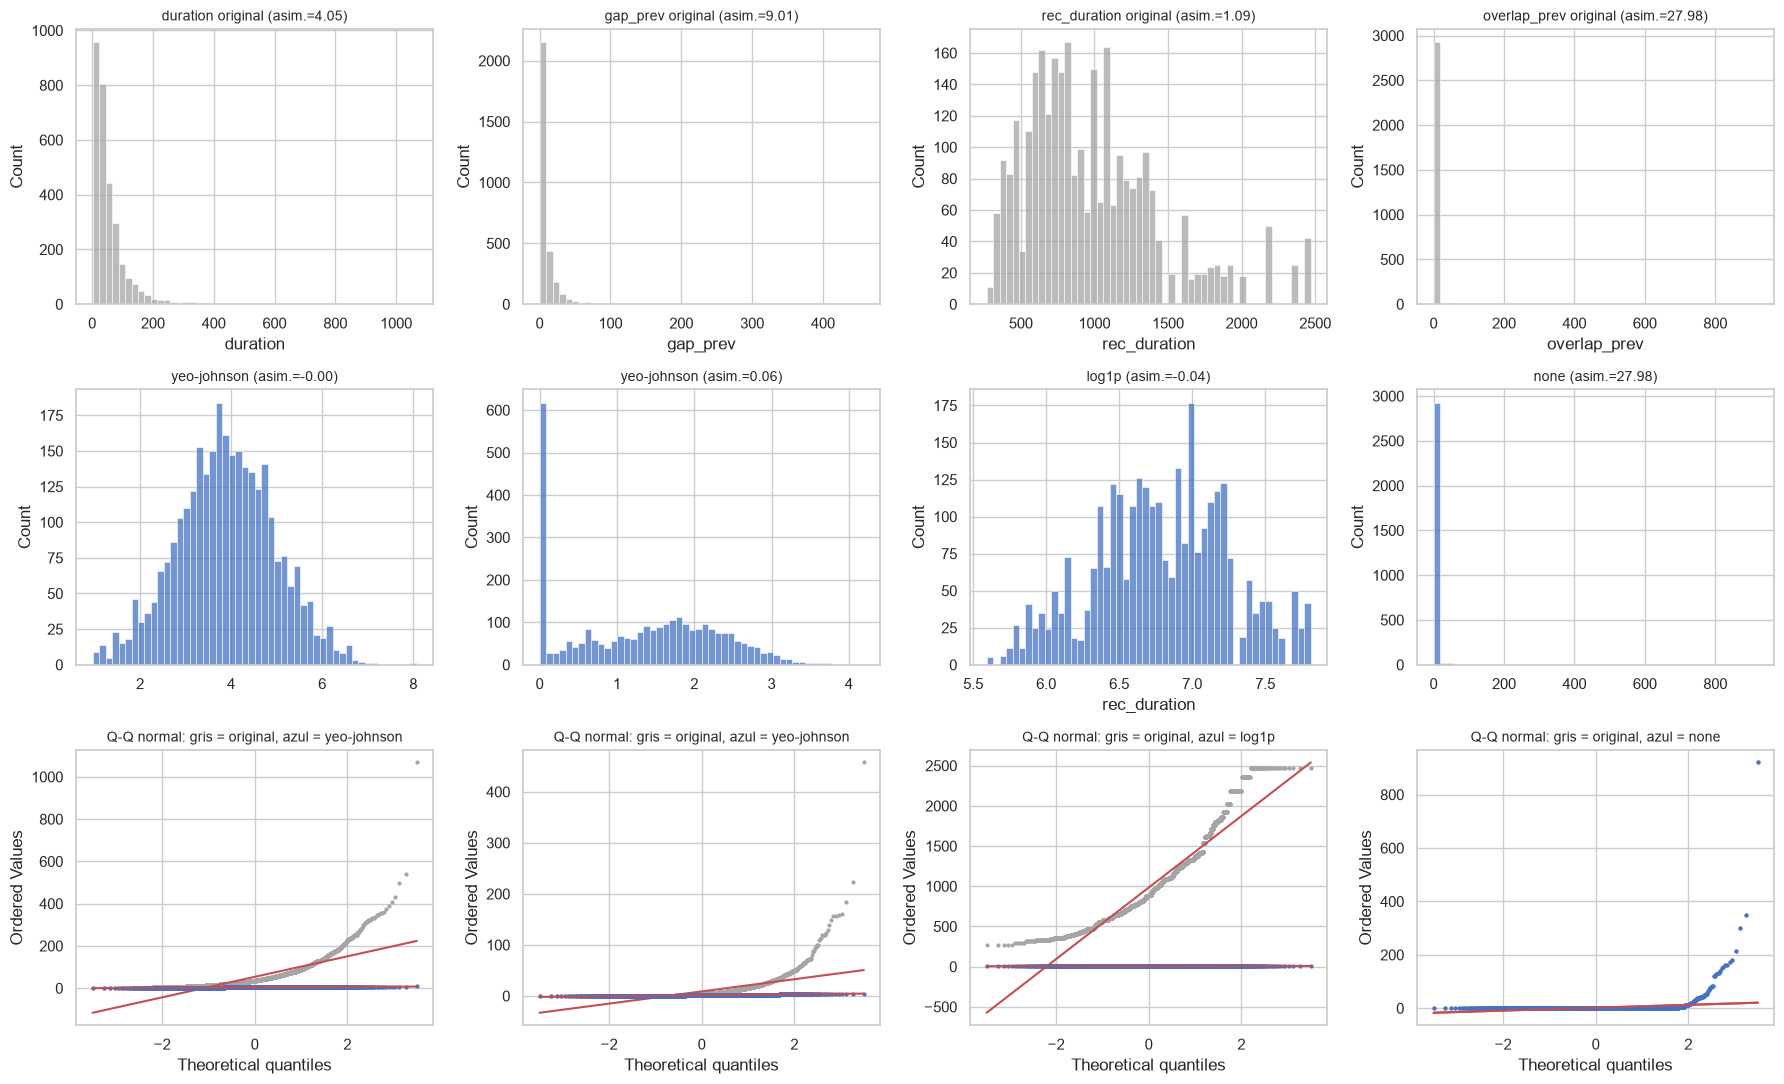

In [20]:
# Tres transformadas y una cero-inflada (sin transformar) como contraste
show = ["duration", "gap_prev", "rec_duration", "overlap_prev"]
fig, axes = plt.subplots(3, 4, figsize=(18, 11))
tfun = {"log1p": lambda x: np.log1p(x),
        "yeo-johnson": lambda x: PowerTransformer(standardize=False).fit_transform(x.to_frame()).ravel(),
        "none": lambda x: x.values}
for j, c in enumerate(show):
    x = eda[c].astype(float)
    xt = tfun[TRANSFORMS[c]](x)
    sns.histplot(x, bins=50, ax=axes[0, j], color="#a5a5a5")
    axes[0, j].set_title(f"{c} original (asim.={stats.skew(x):.2f})", fontsize=10)
    sns.histplot(xt, bins=50, ax=axes[1, j], color="#4472c4")
    axes[1, j].set_title(f"{TRANSFORMS[c]} (asim.={stats.skew(xt):.2f})", fontsize=10)
    stats.probplot(x, dist="norm", plot=axes[2, j])
    stats.probplot(xt, dist="norm", plot=axes[2, j])
    axes[2, j].get_lines()[0].set(color="#a5a5a5", markersize=2)
    axes[2, j].get_lines()[2].set(color="#4472c4", markersize=2)
    axes[2, j].set_title(f"Q-Q normal: gris = original, azul = {TRANSFORMS[c]}", fontsize=10)
plt.tight_layout(); plt.show()

In [21]:
tr_cv = pd.DataFrame([
    cv_row("sin transformar", fe.make_preprocessor(fe.NUMERIC, high_card="freq")),
    cv_row("transformaciones elegidas", fe.make_preprocessor(fe.NUMERIC, TRANSFORMS, high_card="freq")),
]).set_index("configuración")
tr_cv

,columnas,AUC-PR media,desv.,pliegue 1,pliegue 2,pliegue 3,pliegue 4,pliegue 5
configuración,,,,,,,,
sin transformar,46,0.571,0.038,0.632,0.590,0.547,0.519,0.567
transformaciones elegidas,46,0.568,0.036,0.627,0.574,0.544,0.520,0.575


**Justificación :** Se transforman siete numéricas. `duration` (asimetría 4.05), `gap_prev` y `gap_next` (9.01), `n_pred` (2.35) y `exec_idx` (0.64) quedan prácticamente simétricas con Yeo-Johnson (|asimetría| ≤ 0.10), mejor que con `log1p`. En `rec_duration` (1.09), `log1p` queda a menos de 0.1 de Yeo-Johnson (−0.04 contra −0.00) y se prefiere por simplicidad. `dur_z_step` mejora de 42.8 a −4.1, pero sigue asimétrica. Las variables cero-infladas (`repeat_idx`, `overlap_*`, `n_pred_after`, `n_pred_absent` y `rec_repeat_frac`, con 86 % a 99 % de ceros) mantienen asimetrías de 2 a 8 aun con λ extremos, así que no se transforman. En validación cruzada el AUC-PR no cambia más allá del ruido (0.571 sin transformar, 0.568 con las transformaciones; desviación 0.036). Para un modelo lineal la transformación no agrega poder, pero evita que las colas dominen el ajuste, lo que importa para los modelos del avance 3.

### 3.9 Escalamiento: `StandardScaler` vs `RobustScaler`

`StandardScaler` centra con la media y divide entre la desviación estándar; ambas son sensibles a atípicos. `RobustScaler` usa la mediana y el rango intercuartílico. Se compara el rango resultante tras las transformaciones elegidas y el AUC-PR con validación cruzada.

In [22]:
rows = []
for name in ["standard", "robust"]:
    ct = fe.numeric_transformer(TRANSFORMS, scaler=name).set_output(transform="pandas")
    Z = ct.fit_transform(eda[NUM])
    rows.append({"escalador": name, "mediana de |máx|": Z.abs().max().median(),
                 "máximo |valor|": Z.abs().max().max(),
                 "característica con el máximo": Z.abs().max().idxmax(),
                 "% de valores con |z| > 5": 100 * (Z.abs() > 5).to_numpy().mean()})
display(pd.DataFrame(rows).set_index("escalador"))

sc_cv = pd.DataFrame([
    cv_row("StandardScaler", fe.make_preprocessor(fe.NUMERIC, TRANSFORMS, "standard", high_card="freq")),
    cv_row("RobustScaler", fe.make_preprocessor(fe.NUMERIC, TRANSFORMS, "robust", high_card="freq")),
]).set_index("configuración")
sc_cv

,mediana de |máx|,máximo |valor|,característica con el máximo,% de valores con |z| > 5
escalador,,,,
standard,3.846,41.663,overlap_next,0.197
robust,1.859,920.561,overlap_prev,0.376


,columnas,AUC-PR media,desv.,pliegue 1,pliegue 2,pliegue 3,pliegue 4,pliegue 5
configuración,,,,,,,,
StandardScaler,46,0.568,0.036,0.627,0.574,0.544,0.520,0.575
RobustScaler,46,0.562,0.043,0.644,0.547,0.537,0.520,0.566


**Justificación :** Tras las transformaciones quedan variables con colas largas sin transformar (los traslapes). `RobustScaler` divide entre el rango intercuartílico, que vale 0 en las variables con más de 75 % de ceros; scikit-learn conserva entonces la escala original y aparecen valores de hasta 921 (`overlap_prev`), contra un máximo de 42 con `StandardScaler`. En validación cruzada `StandardScaler` es ligeramente mejor (0.568 contra 0.562) y más estable (desviación 0.036 contra 0.043). Se elige **StandardScaler**.

## 4. Selección y extracción de características (B)

Se parte de la matriz completa con las decisiones de la sección 3 (ajustada solo con entrenamiento):

In [23]:
HIGH_CARD = "freq"
SCALER = "standard"
pre_full = fe.make_preprocessor(fe.NUMERIC, TRANSFORMS, SCALER, high_card=HIGH_CARD)
X = pre_full.fit_transform(train, y)
# Misma matriz antes de transformar y escalar (para la prueba de varianza)
X_raw = clone(pre_full.named_steps["features"]).set_output(transform="pandas").fit_transform(train, y)

NUM_COLS = fe.NUMERIC + ["step_id_freq", "verb_norm_freq"]
BIN_COLS = fe.BINARY
ACT_COLS = [c for c in X.columns if c.startswith("activity_name_")]
print("Matriz completa:", X.shape, "| numéricas:", len(NUM_COLS), "| binarias:", len(BIN_COLS),
      "| one-hot de receta:", len(ACT_COLS))

Matriz completa: (2987, 46) | numéricas: 19 | binarias: 3 | one-hot de receta: 24


### 4.1 Umbral de varianza

- **Binarias y one-hot:** `VarianceThreshold(0.01)`. La varianza de una binaria es p(1 − p); el umbral elimina las que valen 1 en menos de ~1 % de las filas.
- **Numéricas:** la varianza depende de la escala, así que se usa el criterio equivalente de **casi constante**: se elimina si un mismo valor ocupa más del 99 % de las filas.

In [24]:
vt = VarianceThreshold(0.01).fit(X_raw[BIN_COLS + ACT_COLS])
var_bin = pd.DataFrame({"varianza": vt.variances_, "pasa": vt.get_support()}, index=BIN_COLS + ACT_COLS)
mode_share = pd.Series({c: X_raw[c].value_counts(normalize=True).iloc[0] for c in NUM_COLS})
var_num = pd.DataFrame({"% del valor más frecuente": 100 * mode_share, "pasa": mode_share <= 0.99})
print("Binarias/one-hot que no pasan:", var_bin.index[~var_bin["pasa"]].tolist())
print("Numéricas casi constantes:", var_num.index[~var_num["pasa"]].tolist())
display(var_bin.sort_values("varianza").head(6))
var_num.sort_values("% del valor más frecuente", ascending=False).head(6)

Binarias/one-hot que no pasan: []
Numéricas casi constantes: []


,varianza,pasa
activity_name_Spiced Hot Chocolate,0.019,True
activity_name_Butter Corn Cup,0.027,True
activity_name_Cheese Pimiento,0.027,True
activity_name_Microwave French Toast,0.028,True
order_violation,0.029,True
activity_name_Tomato Mozzarella Salad,0.029,True


,% del valor más frecuente,pasa
repeat_idx,98.661,True
n_pred_after,97.054,True
n_pred_absent,95.849,True
overlap_next,91.697,True
overlap_prev,91.697,True
rec_repeat_frac,86.140,True


**Justificación :** Ninguna característica se elimina por varianza. La binaria más rara es `order_violation` (2.9 % de unos, varianza 0.029) y la receta con menos pasos es *Spiced Hot Chocolate* (varianza 0.019); ambas están por encima de 0.01. Entre las numéricas, la más cercana a constante es `repeat_idx`, con 98.7 % de ceros, por debajo del límite de 99 %. Las características se construyeron a partir de fenómenos que ocurren con una frecuencia mínima, así que este filtro no descarta nada aquí.

### 4.2 Matriz de correlación

Se usa **Spearman** (relación monótona; no cambia con transformaciones monótonas como `log1p` y es robusta a atípicos). **Criterio:** en cada par con |ρ| > 0.9 se elimina la característica con menor información mutua con `has_errors` (si empatan, la de menor ANOVA F); los pares se resuelven del más correlacionado al menos.

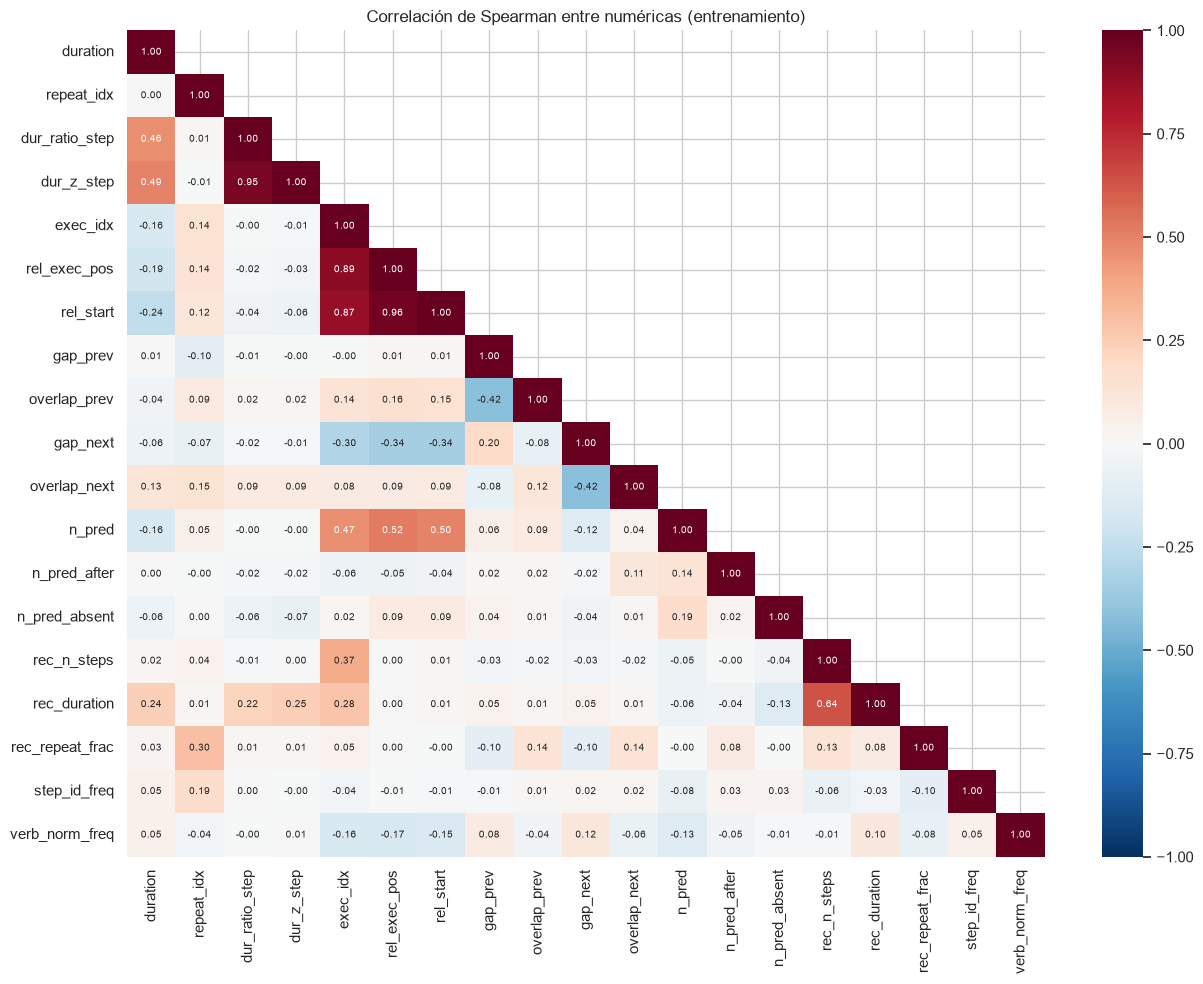

Pares con |ρ| > 0.9:


,var_1,var_2,spearman
0,rel_exec_pos,rel_start,0.962
1,dur_ratio_step,dur_z_step,0.946


Se eliminan: {'rel_start': '|ρ| = 0.96 con rel_exec_pos; menor información mutua (0.0000 < 0.0141)', 'dur_z_step': '|ρ| = 0.95 con dur_ratio_step; menor información mutua (0.0000 < 0.0149)'}


In [25]:
# Información mutua: las numéricas con pocos valores distintos (<= 30) se tratan como discretas;
# el estimador de k vecinos falla con muchos empates.
DISCRETE = (X[NUM_COLS].nunique() <= 30).to_numpy()
MI = pd.Series(mutual_info_classif(X[NUM_COLS], y, discrete_features=DISCRETE, random_state=SEED),
               index=NUM_COLS)
F, p_F = f_classif(X[NUM_COLS], y)
F = pd.Series(F, index=NUM_COLS)
rho = X[NUM_COLS].corr(method="spearman")

fig, ax = plt.subplots(figsize=(13, 10))
sns.heatmap(rho, mask=np.triu(np.ones_like(rho, dtype=bool), k=1), annot=True, fmt=".2f",
            cmap="RdBu_r", center=0, vmin=-1, vmax=1, annot_kws={"size": 7}, ax=ax)
ax.set_title("Correlación de Spearman entre numéricas (entrenamiento)")
plt.tight_layout(); plt.show()

pairs = [(a, b, rho.loc[a, b]) for i, a in enumerate(NUM_COLS) for b in NUM_COLS[i + 1:]
         if abs(rho.loc[a, b]) > 0.9]
pairs.sort(key=lambda t: -abs(t[2]))
DROP_CORR = {}
for a, b, r in pairs:
    if a in DROP_CORR or b in DROP_CORR:
        continue
    if abs(MI[a] - MI[b]) > 1e-4:
        lose, keep = (a, b) if MI[a] < MI[b] else (b, a)
        crit = f"menor información mutua ({MI[lose]:.4f} < {MI[keep]:.4f})"
    else:  # empate en información mutua: se desempata con ANOVA F
        lose, keep = (a, b) if F[a] < F[b] else (b, a)
        crit = f"misma información mutua; menor ANOVA F ({F[lose]:.1f} < {F[keep]:.1f})"
    DROP_CORR[lose] = f"|ρ| = {abs(r):.2f} con {keep}; {crit}"
print("Pares con |ρ| > 0.9:")
display(pd.DataFrame(pairs, columns=["var_1", "var_2", "spearman"]))
print("Se eliminan:", DROP_CORR)

**Justificación :** Solo dos pares superan |ρ| = 0.9: `rel_exec_pos`–`rel_start` (0.96) y `dur_ratio_step`–`dur_z_step` (0.95). Se eliminan `rel_start` (información mutua 0.000 contra 0.014) y `dur_z_step` (0.000 contra 0.015). La segunda confirma lo visto en las secciones 3.1 y 3.8: el cociente contra la mediana conserva la información del *z-score* sin su inestabilidad.

### 4.3 ANOVA F e información mutua contra `has_errors`

- **ANOVA F** (`f_classif`): diferencia de medias entre clases; detecta relaciones lineales.
- **Información mutua**: detecta cualquier dependencia, incluida la no lineal. Su estimador nunca da exactamente 0 y su sesgo depende de cuántos valores distintos tiene la variable, así que se prueba con **permutaciones**: se recalcula con la etiqueta permutada al azar 30 veces y el valor p es la fracción de permutaciones que igualan o superan el valor observado.

**Criterio:** una numérica se elimina por irrelevante solo si **ninguna** de las dos pruebas encuentra relación (ANOVA p ≥ 0.05 **y** p de permutación de la información mutua ≥ 0.05).

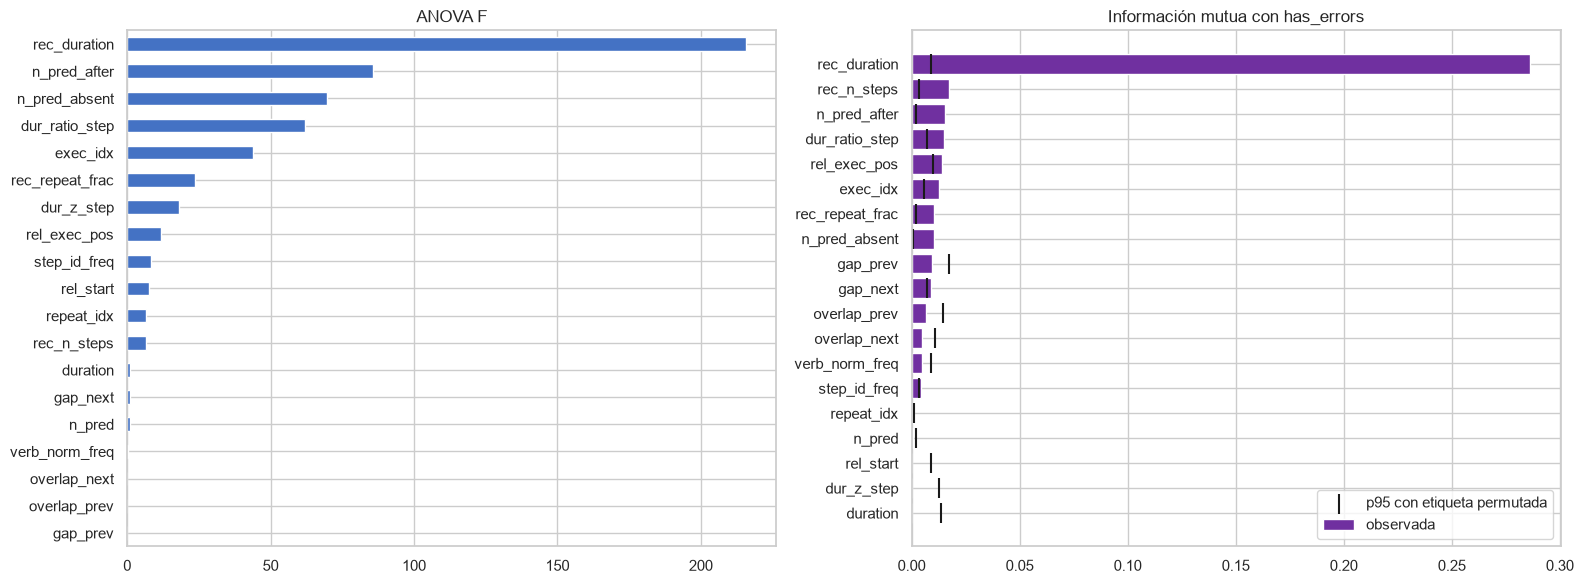

,discreta,F,p_ANOVA,información_mutua,ruido_MI_p95,p_permutación_MI,sin relación
rec_duration,False,215.576,0.000,0.286,0.009,0.032,False
rec_n_steps,True,6.567,0.010,0.017,0.004,0.032,False
n_pred_after,True,85.729,0.000,0.015,0.002,0.032,False
dur_ratio_step,False,61.985,0.000,0.015,0.007,0.032,False
rel_exec_pos,False,11.873,0.001,0.014,0.010,0.032,False
exec_idx,True,44.021,0.000,0.012,0.006,0.032,False
rec_repeat_frac,True,23.672,0.000,0.010,0.002,0.032,False
n_pred_absent,True,69.826,0.000,0.010,0.001,0.032,False
gap_prev,False,0.002,0.968,0.010,0.017,0.161,True
gap_next,False,0.913,0.339,0.009,0.007,0.065,True


In [26]:
N_PERM = 30
rng = np.random.default_rng(SEED)
null = np.array([mutual_info_classif(X[NUM_COLS], rng.permutation(y.values), discrete_features=DISCRETE,
                                     random_state=SEED) for _ in range(N_PERM)])
p_MI = (1 + (null >= MI.to_numpy()).sum(axis=0)) / (1 + N_PERM)
MI_NOISE = pd.Series(np.percentile(null, 95, axis=0), index=NUM_COLS)
rel = pd.DataFrame({"discreta": DISCRETE, "F": F, "p_ANOVA": p_F, "información_mutua": MI,
                    "ruido_MI_p95": MI_NOISE, "p_permutación_MI": p_MI}, index=NUM_COLS)
rel["sin relación"] = (rel["p_ANOVA"] >= 0.05) & (rel["p_permutación_MI"] >= 0.05)

fig, axes = plt.subplots(1, 2, figsize=(16, 6))
rel["F"].sort_values().plot.barh(ax=axes[0], color="#4472c4"); axes[0].set_title("ANOVA F")
order_mi = rel["información_mutua"].sort_values().index
axes[1].barh(order_mi, rel.loc[order_mi, "información_mutua"], color="#7030a0", label="observada")
axes[1].scatter(rel.loc[order_mi, "ruido_MI_p95"], order_mi, color="k", marker="|", s=200,
                label="p95 con etiqueta permutada")
axes[1].legend()
axes[1].set_title("Información mutua con has_errors")
plt.tight_layout(); plt.show()
rel.sort_values("información_mutua", ascending=False)

**Justificación :** Diez numéricas muestran relación en las dos pruebas (ANOVA p < 0.05 y p de permutación de la información mutua = 0.03, el mínimo posible con 30 permutaciones). `rec_duration` destaca (F = 216, MI = 0.29), aunque su información mutua está inflada porque es constante dentro de cada grabación (ver 3.5). `dur_z_step` y `rel_start` solo son significativas en ANOVA (p de permutación = 1.0) y ya se eliminaron por redundancia. Siete no muestran relación en ninguna prueba: `duration`, `gap_prev`, `gap_next`, `overlap_prev`, `overlap_next`, `n_pred` y `verb_norm_freq`.

### 4.4 χ² para las categóricas

Se aplica la prueba de independencia χ² a cada categórica y binaria contra `has_errors`, con la **V de Cramér** como tamaño del efecto. Se reporta el % de celdas con frecuencia esperada < 5, porque con muchas clases pequeñas la aproximación χ² pierde validez. Para `activity_name` también se usa `sklearn.feature_selection.chi2` sobre sus columnas one-hot. **Criterio:** se conserva la variable (o el bloque de columnas one-hot) si p < 0.05.

In [27]:
rows = []
for c in ["activity_name", "verb_norm", "step_id"] + BIN_COLS:
    ct = pd.crosstab(train[c], y)
    chi2_, p, dof, exp = stats.chi2_contingency(ct)
    v = np.sqrt(chi2_ / (ct.values.sum() * (min(ct.shape) - 1)))
    rows.append({"variable": c, "clases": ct.shape[0], "chi2": chi2_, "gl": dof, "p": p, "V de Cramér": v,
                 "% celdas esperadas < 5": 100 * (exp < 5).mean()})
chi_t = pd.DataFrame(rows).set_index("variable")
display(chi_t)

chi_act, p_act = chi2(X_raw[ACT_COLS], y)
print(f"activity_name one-hot: {(p_act < 0.05).sum()} de {len(ACT_COLS)} columnas con p < 0.05 (chi2 de sklearn)")

,clases,chi2,gl,p,V de Cramér,% celdas esperadas < 5
variable,,,,,,
activity_name,24,183.553,23,0.000,0.248,0.000
verb_norm,76,139.040,75,0.000,0.216,38.158
step_id,350,461.498,349,0.000,0.393,54.000
is_first,2,2.949,1,0.086,0.031,0.000
is_last,2,3.608,1,0.057,0.035,0.000
order_violation,2,103.090,1,0.000,0.186,0.000


activity_name one-hot: 9 de 24 columnas con p < 0.05 (chi2 de sklearn)


**Justificación :** `activity_name` (V = 0.25), `verb_norm` (0.22), `step_id` (0.39) y `order_violation` (0.19) rechazan la independencia con p < 0.001; `is_first` (p = 0.09) e `is_last` (p = 0.06) no. En `verb_norm` y `step_id` la prueba no es confiable (38 % y 54 % de celdas con frecuencia esperada < 5), así que esas dos variables se deciden por su codificación numérica en 4.3, donde `verb_norm_freq` no muestra relación. De las 24 columnas one-hot de receta, 9 tienen p < 0.05 por separado. Se conservan como bloque, porque la variable completa es significativa y quitar columnas sueltas mezclaría esas recetas en un grupo implícito.

### 4.5 Extracción: PCA sobre las numéricas escaladas

PCA se ajusta con entrenamiento sobre las numéricas ya transformadas y escaladas. Se reporta la varianza explicada acumulada, cuántos componentes alcanzan el 90 % y el 95 %, y el AUC-PR de un modelo solo con numéricas, con y sin PCA.

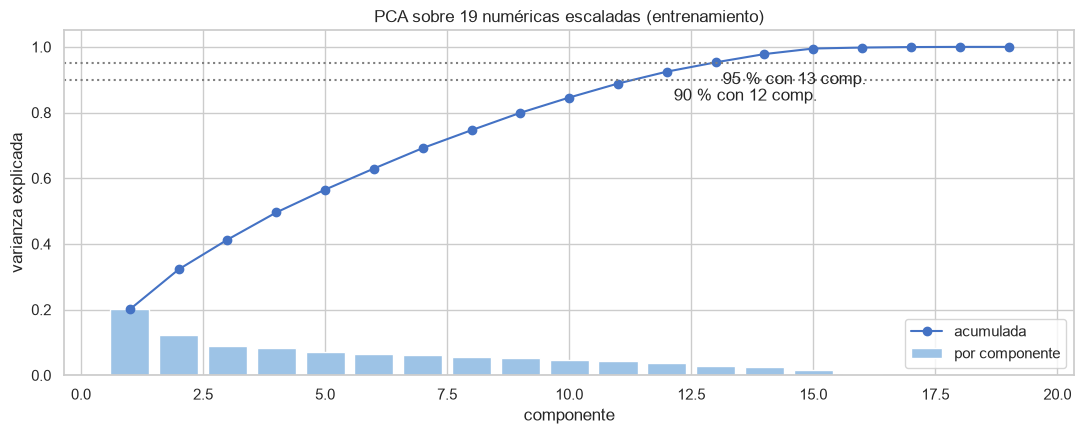

Componentes para 90 %: 12 de 19 | para 95 %: 13 de 19


,AUC-PR media,desv.
configuración,,
numéricas sin PCA,0.547,0.047
PCA 13 componentes (95 %),0.477,0.059
PCA 12 componentes (90 %),0.466,0.053


In [28]:
pca = PCA(random_state=SEED).fit(X[NUM_COLS])
cum = np.cumsum(pca.explained_variance_ratio_)
K90, K95 = int(np.searchsorted(cum, 0.90) + 1), int(np.searchsorted(cum, 0.95) + 1)

fig, ax = plt.subplots(figsize=(11, 4.5))
ax.bar(range(1, len(cum) + 1), pca.explained_variance_ratio_, color="#9dc3e6", label="por componente")
ax.plot(range(1, len(cum) + 1), cum, marker="o", color="#4472c4", label="acumulada")
for t, k in [(0.90, K90), (0.95, K95)]:
    ax.axhline(t, color="gray", ls=":"); ax.annotate(f"{int(t * 100)} % con {k} comp.", (k, t), xytext=(5, -15),
                                                    textcoords="offset points")
ax.set_xlabel("componente"); ax.set_ylabel("varianza explicada"); ax.legend()
ax.set_title(f"PCA sobre {len(NUM_COLS)} numéricas escaladas (entrenamiento)")
plt.tight_layout(); plt.show()
print(f"Componentes para 90 %: {K90} de {len(NUM_COLS)} | para 95 %: {K95} de {len(NUM_COLS)}")

num_only = fe.make_preprocessor(fe.NUMERIC, TRANSFORMS, SCALER, high_card="freq", binary=[], low_card=[])
lr = LogisticRegression(class_weight="balanced", max_iter=5000)
pca_cv = []
for name, est in [("numéricas sin PCA", Pipeline([("prep", num_only), ("clf", lr)])),
                  (f"PCA {K95} componentes (95 %)", Pipeline([("prep", num_only), ("pca", PCA(K95, random_state=SEED)), ("clf", lr)])),
                  (f"PCA {K90} componentes (90 %)", Pipeline([("prep", num_only), ("pca", PCA(K90, random_state=SEED)), ("clf", lr)]))]:
    s = fe.grouped_cv_auc_pr(est, train, y)
    pca_cv.append({"configuración": name, "AUC-PR media": s.mean(), "desv.": s.std()})
pd.DataFrame(pca_cv).set_index("configuración")

**Justificación :** Hacen falta 12 de 19 componentes para el 90 % de la varianza y 13 para el 95 %. Las numéricas están poco correlacionadas (solo dos pares superan |ρ| = 0.9), así que PCA comprime poco. Además, en validación cruzada el modelo solo con numéricas baja de 0.547 a 0.477 con 13 componentes: PCA no mira la etiqueta, y los componentes de mayor varianza no son los que separan las clases. **No se usa PCA** en el pipeline. Se conserva como diagnóstico de redundancia y por la interpretabilidad que exige el producto: cada advertencia debe poder explicarse con una característica concreta.

### 4.6 Tabla final de selección

Se aplican, en orden, los criterios de las secciones 4.1 a 4.4:

1. **Varianza:** casi constante (numérica) o varianza < 0.01 (binaria) → se elimina.
2. **Redundancia:** |ρ| > 0.9 con otra característica y menor información mutua → se elimina.
3. **Relevancia:** numérica sin relación en ANOVA ni en información mutua; categórica o binaria con χ² p ≥ 0.05 → se elimina.

PCA no se usa como paso del modelo (ver 4.5).

In [29]:
rows = []
for c in X.columns:
    block = "activity_name" if c in ACT_COLS else c
    kind = "numérica" if c in NUM_COLS else ("binaria" if c in BIN_COLS else "one-hot (receta)")
    if c in NUM_COLS and not var_num.loc[c, "pasa"]:
        decision, why = "elimina", f"casi constante ({var_num.loc[c, '% del valor más frecuente']:.1f} % un mismo valor)"
    elif c in var_bin.index and not var_bin.loc[c, "pasa"]:
        decision, why = "elimina", f"varianza {var_bin.loc[c, 'varianza']:.4f} < 0.01"
    elif c in DROP_CORR:
        decision, why = "elimina", "redundante: " + DROP_CORR[c]
    elif c in NUM_COLS and rel.loc[c, "sin relación"]:
        decision, why = "elimina", (f"sin relación: ANOVA p = {rel.loc[c, 'p_ANOVA']:.2f}, "
                                    f"MI = {rel.loc[c, 'información_mutua']:.4f}, p perm. = {rel.loc[c, 'p_permutación_MI']:.2f}")
    elif block in chi_t.index and chi_t.loc[block, "p"] >= 0.05:
        decision, why = "elimina", f"χ² p = {chi_t.loc[block, 'p']:.2f}"
    elif c in NUM_COLS:
        decision, why = "conserva", (f"ANOVA p = {rel.loc[c, 'p_ANOVA']:.2g}, MI = {rel.loc[c, 'información_mutua']:.4f}"
                                     f" (p perm. = {rel.loc[c, 'p_permutación_MI']:.2f})")
    else:
        decision, why = "conserva", f"χ² p = {chi_t.loc[block, 'p']:.2g}, V = {chi_t.loc[block, 'V de Cramér']:.2f}"
    rows.append({"característica": c, "tipo": kind, "decisión": decision, "por qué": why})
final = pd.DataFrame(rows).set_index("característica")
SELECTED = final.index[final["decisión"] == "conserva"].tolist()

with pd.option_context("display.max_colwidth", 120, "display.max_rows", 100):
    display(final[~final.index.isin(ACT_COLS)])
act = final.loc[ACT_COLS, "decisión"].value_counts().to_dict()
print(f"activity_name (24 columnas one-hot, se deciden como bloque): {act}")
print(f"Se conservan {len(SELECTED)} de {X.shape[1]} columnas")

,tipo,decisión,por qué
característica,,,
rec_duration,numérica,conserva,"ANOVA p = 3.5e-47, MI = 0.2862 (p perm. = 0.03)"
duration,numérica,elimina,"sin relación: ANOVA p = 0.31, MI = 0.0000, p perm. = 1.00"
dur_z_step,numérica,elimina,redundante: |ρ| = 0.95 con dur_ratio_step; menor información mutua (0.0000 < 0.0149)
exec_idx,numérica,conserva,"ANOVA p = 3.8e-11, MI = 0.0125 (p perm. = 0.03)"
gap_prev,numérica,elimina,"sin relación: ANOVA p = 0.97, MI = 0.0096, p perm. = 0.16"
gap_next,numérica,elimina,"sin relación: ANOVA p = 0.34, MI = 0.0088, p perm. = 0.06"
n_pred,numérica,elimina,"sin relación: ANOVA p = 0.35, MI = 0.0006, p perm. = 0.87"
repeat_idx,numérica,conserva,"ANOVA p = 0.0096, MI = 0.0011 (p perm. = 0.03)"
dur_ratio_step,numérica,conserva,"ANOVA p = 4.8e-15, MI = 0.0149 (p perm. = 0.03)"


activity_name (24 columnas one-hot, se deciden como bloque): {'conserva': 24}
Se conservan 35 de 46 columnas


**Justificación :** De 46 columnas se conservan 35: 10 numéricas, `order_violation` y el bloque de 24 columnas de receta. Se eliminan 11: 2 por redundancia (`rel_start` y `dur_z_step`), 7 numéricas sin relación en ninguna prueba y 2 binarias con χ² no significativo (`is_first` e `is_last`). Ninguna se eliminó por varianza.

### 4.7 Comprobación: todas las características vs las seleccionadas

AUC-PR con `GroupKFold` (5 pliegues por grabación) de la misma regresión logística, ajustando todo el pipeline dentro de cada pliegue. **Solo es evidencia de la selección**, no el *baseline* del avance 3. La selección se decidió con todo el conjunto de entrenamiento, así que esta comparación puede ser ligeramente optimista para las seleccionadas.

In [30]:
check_cv = pd.DataFrame([
    cv_row("todas", fe.make_preprocessor(fe.NUMERIC, TRANSFORMS, SCALER, high_card=HIGH_CARD)),
    cv_row("seleccionadas", fe.make_preprocessor(fe.NUMERIC, TRANSFORMS, SCALER, high_card=HIGH_CARD, select=SELECTED)),
]).set_index("configuración")
folds = [c for c in check_cv if c.startswith("pliegue")]
diff = check_cv.loc["seleccionadas", folds] - check_cv.loc["todas", folds]
print(f"AUC-PR sin información = {BASE_AP:.3f}")
print("Diferencia por pliegue (seleccionadas − todas):", np.round(diff.values.astype(float), 3))
check_cv[["columnas", "AUC-PR media", "desv."] + folds]

AUC-PR sin información = 0.249
Diferencia por pliegue (seleccionadas − todas): [-0.015  0.003 -0.018 -0.023 -0.023]


,columnas,AUC-PR media,desv.,pliegue 1,pliegue 2,pliegue 3,pliegue 4,pliegue 5
configuración,,,,,,,,
todas,46,0.568,0.036,0.627,0.574,0.544,0.520,0.575
seleccionadas,35,0.553,0.040,0.612,0.577,0.526,0.498,0.552


**Diagnóstico de lo que se pierde.** Los filtros evalúan cada característica por separado. Para ver si alguna eliminada aporta en combinación con las demás, se agrega cada una, de a una, al conjunto seleccionado (también con GroupKFold). Es solo un diagnóstico para el avance 3, donde corresponde probar métodos de envoltura y embebidos (p. ej. regularización L1); la selección de este avance no se modifica con él.

In [31]:
DROPPED = final.index[final["decisión"] == "elimina"].tolist()
base_sel = check_cv.loc["seleccionadas", "AUC-PR media"]
abl = []
for c in DROPPED:
    s_ = fe.grouped_cv_auc_pr(fe.make_model(fe.make_preprocessor(
        fe.NUMERIC, TRANSFORMS, SCALER, high_card=HIGH_CARD, select=SELECTED + [c])), train, y)
    abl.append({"se agrega": c, "AUC-PR media": s_.mean(), "Δ vs seleccionadas": s_.mean() - base_sel})
pd.DataFrame(abl).set_index("se agrega").sort_values("Δ vs seleccionadas", ascending=False)

,AUC-PR media,Δ vs seleccionadas
se agrega,,
duration,0.571,0.017
gap_prev,0.557,0.004
is_first,0.555,0.002
gap_next,0.554,0.001
overlap_prev,0.553,0.000
is_last,0.553,0.000
verb_norm_freq,0.552,-0.001
rel_start,0.552,-0.001
n_pred,0.552,-0.001


**Justificación :** Las seleccionadas pierden 0.015 de AUC-PR (0.553 contra 0.568) con 24 % menos columnas (35 contra 46). La diferencia es menor que la desviación entre pliegues (≈ 0.04), pero aparece en 4 de 5 pliegues, así que no es solo ruido. El diagnóstico la explica casi por completo: al volver a agregar `duration`, el AUC-PR sube a 0.571, igual que con todas. `duration` no tiene relación por sí sola (ANOVA p = 0.31), pero junto con `dur_ratio_step` permite reconstruir la duración típica de cada paso, una interacción que los filtros univariados no detectan. Las otras 10 eliminadas cambian el AUC-PR en 0.005 o menos, lo que respalda su eliminación. Se recomienda evaluar `duration` en el avance 3 con un método de envoltura o embebido, en lugar de reincorporarla aquí: decidirlo con esta misma validación cruzada sesgaría la comparación.

## 5. Pipeline final y aplicación a validación y prueba

Las decisiones de este avance quedan fijadas en `sopvid.features.engineering` (`FINAL_TRANSFORMS`, `FINAL_SCALER`, `FINAL_HIGH_CARD` y `FINAL_SELECTED`). `fe.build_features(train, test)` construye las características, ajusta el pipeline **solo con entrenamiento** y transforma la otra partición. Es la entrada del avance 3.

Primero se verifica que el paquete tenga exactamente las decisiones tomadas en este notebook. De validación y prueba solo se revisa la forma y la ausencia de valores faltantes, **sin mirar sus etiquetas**.

In [32]:
fs = fe.build_features(parts["train"], parts["test"], video_info=raw.video_info, task_graphs=graphs)

assert fe.FINAL_TRANSFORMS == TRANSFORMS, "FINAL_TRANSFORMS no coincide con la sección 3.8"
assert fe.FINAL_SCALER == SCALER and fe.FINAL_HIGH_CARD == HIGH_CARD, "no coincide con 3.6 / 3.9"
assert list(fs.X_train.columns) == SELECTED, "las columnas de build_features no coinciden con 4.6"
assert np.allclose(fs.X_train.to_numpy(), X[SELECTED].to_numpy()), "X_train difiere de la sección 4"
print("build_features reproduce las decisiones y la matriz de entrenamiento de este notebook.")

X_val = fs.pipeline.transform(fe.prepare_steps(parts["val"], raw.video_info, graphs))
pd.DataFrame({
    "filas (pasos ejecutados)": [len(fs.X_train), len(X_val), len(fs.X_test)],
    "columnas": [fs.X_train.shape[1], X_val.shape[1], fs.X_test.shape[1]],
    "valores faltantes": [int(fs.X_train.isna().sum().sum()), int(X_val.isna().sum().sum()),
                          int(fs.X_test.isna().sum().sum())],
}, index=["train", "val", "test"])

build_features reproduce las decisiones y la matriz de entrenamiento de este notebook.


,filas (pasos ejecutados),columnas,valores faltantes
train,2987,35,0
val,884,35,0
test,1542,35,0


In [33]:
print("Pipeline ajustado con entrenamiento:")
fs.pipeline

Pipeline ajustado con entrenamiento:


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('features', ...), ('scale', ...), ...]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](46,)","['recording_id','activity_id','activity_name',...,'rec_n_steps', 'rec_duration','rec_repeat_frac']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,46
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('dur', ...), ('num', ...), ...]"
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It is equivalent to setting `verbose_feature_names_out=""{transformer_name}__{feature_name}""`.- If False, :meth:`ColumnTransformer.get_feature_names_out` w

## 6. Conclusiones (C)

### Preparación de los datos según CRISP-ML(Q)

En esta fase el objetivo fue dejar los datos listos para modelar, siguiendo las cuatro tareas que propone CRISP-ML(Q): seleccionar, limpiar, construir y estandarizar.

Decidimos trabajar solo con los pasos ejecutados (2,987 en entrenamiento, 24.9 % con error). Los pasos omitidos los quitamos porque casi todos (98.2 %) tienen error y le darían la respuesta al modelo. Después aplicamos filtros de varianza, correlación, ANOVA, información mutua y χ², y pasamos de 46 a 35 columnas. Probamos PCA, pero no lo usamos: comprime poco, baja el desempeño y haría más difícil explicar las advertencias del copiloto.

Corregimos una fuga que venía del avance 1 en el cálculo de la duración típica de cada paso. Además, todo lo que aprende de los datos se ajusta solo con entrenamiento y la validación se agrupa por grabación.

Las mejores características salieron del conocimiento del dominio. Lo importante no es cuánto dura un paso, sino si duró menos de lo normal: los pasos con error son alrededor de 14 % más cortos que lo típico. También usamos el orden de la receta, y los pasos hechos en desorden tienen 71.6 % de error contra 23.5 % del resto.

Usamos one-hot para la receta, frecuencia para las categóricas con muchas clases, Yeo-Johnson o log1p para las variables asimétricas y StandardScaler para todas. Cuando dos opciones daban prácticamente lo mismo, elegimos la más simple.

Los riesgos para el siguiente avance consideramos que la característica más fuerte, rec_duration, depende de cómo se armó el dataset y probablemente no funcione igual en la planta del cliente. Por eso en el avance 3 vamos a comparar el modelo con y sin ella. También vamos a revisar duration, que los filtros eliminaron pero que ayuda cuando se combina con la duración relativa.

Con esto cerramos la preparación de los datos con una matriz de 35 columnas, sin valores faltantes ni fuga de información, lista para la fase de modelado.

**Hallazgos con números** :

1. **Unidad de análisis y fuga.** El modelo usa 2,987 pasos ejecutados de 213 grabaciones de entrenamiento, con 24.9 % de error (AUC-PR de referencia 0.249). Los 171 pasos omitidos se excluyen porque el 98.2 % tiene error (`is_skipped` revelaría la etiqueta).
2. **Corrección de una fuga del avance 1.** La duración típica de cada paso ahora se calcula fuera de pliegue (GroupKFold por grabación). Con la mediana de la misma muestra, 173 pasos ejecutados tenían `dur_ratio_step` = 0 de forma artificial; ahora ninguno.
3. **Duración relativa.** La duración absoluta no distingue errores (p = 0.18), pero la relativa a su paso sí: los pasos con error duran alrededor de 14 % menos que lo típico (biserial −0.19, p < 0.001). El cociente se prefirió al *z-score* (ρ = 0.95 entre ambos; asimetría del *z-score* 42.8).
4. **Orden de la receta.** Los grafos de tareas permiten detectar inversiones: 2.9 % de los pasos, con 71.6 % de error frente a 23.5 % (χ² = 103). Detectan el 21.1 % de los *Order Error*.
5. **Posición.** Los errores ocurren antes en la ejecución (mediana de `exec_idx` 5 contra 7). Las banderas de primer y último paso no son significativas (p = 0.09 y 0.06).
6. **Contexto temporal.** Huecos y traslapes con los pasos vecinos no se relacionan con el error (|biserial| ≤ 0.03) y se eliminan.
7. **Nivel grabación: riesgo principal.** `rec_duration` concentra la señal: sin ella el AUC-PR baja de 0.571 a 0.485, y solo con las variables de grabación y la receta se logra 0.508. El 45.1 % de las grabaciones no tiene errores y el 28.2 % los tiene en más de la mitad de sus pasos (diseño del dataset). Es un posible artefacto que no se transferiría a la planta.
8. **Alta cardinalidad.** Frecuencia, *target encoding* y one-hot empatan (0.559 a 0.572; desviación ≈ 0.04). El *target encoding* con m = 1 empeora en los 5 pliegues. Se eligió frecuencia (2 columnas, no usa la etiqueta).
9. **Baja cardinalidad.** One-hot de la receta 0.571, frente a ordinal 0.535 y sin la variable 0.536.
10. **Transformaciones.** Se transforman 7 numéricas (6 con Yeo-Johnson y `rec_duration` con `log1p`); la asimetría de `duration` pasa de 4.05 a 0.00. Las cero-infladas no se transforman. El AUC-PR no cambia (0.571 contra 0.568).
11. **Escalamiento.** `StandardScaler` (0.568) frente a `RobustScaler` (0.562); el robusto deja valores de hasta 921 donde el rango intercuartílico es 0.
12. **Selección.** De 46 columnas quedan 35: 0 eliminadas por varianza, 2 por redundancia, 7 numéricas sin relación (ANOVA e información mutua con permutaciones) y 2 binarias por χ².
13. **Extracción.** PCA necesita 12 de 19 componentes para el 90 % y 13 para el 95 %, y baja el AUC-PR de 0.547 a 0.477, así que no se usa.
14. **Comprobación.** Todas las características dan 0.568 y las seleccionadas 0.553; volver a agregar `duration` recupera 0.571 (interacción con `dur_ratio_step`). Queda como tarea del avance 3, con métodos de envoltura o embebidos.
15. **Pipeline sin fuga.** `sopvid.features.engineering.build_features` ajusta todo solo con entrenamiento y entrega 35 columnas sin faltantes para train (2,987), validación (884) y prueba (1,542 pasos ejecutados). Las etiquetas de validación y prueba no se inspeccionaron.

## Referencias

- Brownlee, J. (2020, 20 de agosto). How to choose a feature selection method for machine learning. *Machine Learning Mastery.*
- Galli, S. (2022). *Python feature engineering cookbook* (2.ª ed.). Packt Publishing.
- Micci-Barreca, D. (2001). A preprocessing scheme for high-cardinality categorical attributes in classification and prediction problems. *ACM SIGKDD Explorations Newsletter, 3*(1), 27–32.
- Peddi, R., et al. (2024). CaptainCook4D: A dataset for understanding errors in procedural activities. *NeurIPS 2024 Datasets and Benchmarks Track.* https://arxiv.org/abs/2312.14556
- Saito, T., y Rehmsmeier, M. (2015). The precision-recall plot is more informative than the ROC plot when evaluating binary classifiers on imbalanced datasets. *PLoS ONE, 10*(3), e0118432.
- Studer, S., Bui, T. B., Drescher, C., Hanuschkin, A., Winkler, L., Peters, S., y Müller, K.-R. (2021). Towards CRISP-ML(Q): A machine learning process model with quality assurance methodology. *Machine Learning and Knowledge Extraction, 3*(2), 392–413.
- Yeo, I.-K., y Johnson, R. A. (2000). A new family of power transformations to improve normality or symmetry. *Biometrika, 87*(4), 954–959.